# EDA Dataset SGCC (State Grid Corporation of China)

Dataset pencurian listrik (electricity theft) dengan label per consumer.  
- **Format**: wide CSV — satu baris = satu consumer  
- **T = 26** timestamp (konsumsi kWh harian, Jan 2014)  
- **FLAG**: 0 = normal, 1 = pencurian  

**Tujuan EDA ini:**
1. Memahami distribusi data (nilai kWh, label, missing)
2. Verifikasi TIDAK ada normalisasi sebelum analisis/injeksi anomali
3. Menghitung window size yang valid untuk pipeline CARLA
4. Visualisasi profil normal vs pencurian

In [10]:
import sys
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Pastikan CARLA root ada di path
CARLA_ROOT = Path('..').resolve()
if str(CARLA_ROOT) not in sys.path:
    sys.path.insert(0, str(CARLA_ROOT))

RAW_ZIP = CARLA_ROOT / 'datasets' / 'SGCC' / 'raw' / 'datasetsmall.csv.zip'
PROCESSED_DIR = CARLA_ROOT / 'datasets' / 'SGCC' / 'processed'
FIG_DIR       = CARLA_ROOT / 'results' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'CARLA root : {CARLA_ROOT}')
print(f'Raw ZIP    : {RAW_ZIP}  exists={RAW_ZIP.exists()}')
print(f'Processed  : {PROCESSED_DIR}  exists={PROCESSED_DIR.exists()}')
print(f'Figure dir : {FIG_DIR}')


CARLA root : D:\CARLA
Raw ZIP    : D:\CARLA\datasets\SGCC\raw\datasetsmall.csv.zip  exists=True
Processed  : D:\CARLA\datasets\SGCC\processed  exists=True
Figure dir : D:\CARLA\results\figures


## 1. Load raw data (kWh asli, TANPA normalisasi)

In [11]:
# Load dari ZIP langsung
with zipfile.ZipFile(RAW_ZIP) as zf:
    csv_names = [n for n in zf.namelist() if n.endswith('.csv')]
    with zf.open(csv_names[0]) as f:
        df = pd.read_csv(f)

META_COLS  = {'CONS_NO', 'FLAG'}
date_cols  = [c for c in df.columns if c not in META_COLS]
T          = len(date_cols)

print(f'Shape      : {df.shape}')
print(f'Consumers  : {len(df):,}')
print(f'Timestamps : {T}  ({date_cols[0]} .. {date_cols[-1]})')
print(f'Columns    : {df.columns.tolist()}')
print(f'\nFLAG distribution:')
print(df['FLAG'].value_counts().rename({0: 'Normal (0)', 1: 'Theft (1)'}))  

# Konfirmasi: raw data BELUM dinormalisasi
raw_vals = df[date_cols].values.astype(float)
print(f'\nNilai kWh (raw, sebelum fill NaN):')
print(f'  min={np.nanmin(raw_vals):.1f}  max={np.nanmax(raw_vals):.1f}  '
      f'mean={np.nanmean(raw_vals):.1f}  std={np.nanstd(raw_vals):.1f}')
print(f'  → Nilai > 1 dan tidak dalam range [0,1]: BENAR, ini raw kWh. ✓')

Shape      : (25863, 28)
Consumers  : 25,863
Timestamps : 26  (01/01/2014 .. 1/26/2014)
Columns    : ['01/01/2014', '01/02/2014', '01/03/2014', '01/04/2014', '01/05/2014', '01/06/2014', '01/07/2014', '01/08/2014', '01/09/2014', '01/10/2014', '01/11/2014', '01/12/2014', '1/13/2014', '1/14/2014', '1/15/2014', '1/16/2014', '1/17/2014', '1/18/2014', '1/19/2014', '1/20/2014', '1/21/2014', '1/22/2014', '1/23/2014', '1/24/2014', '1/25/2014', '1/26/2014', 'CONS_NO', 'FLAG']

FLAG distribution:
FLAG
Normal (0)    23741
Theft (1)      2122
Name: count, dtype: int64

Nilai kWh (raw, sebelum fill NaN):
  min=0.0  max=514991.8  mean=8.0  std=639.2
  → Nilai > 1 dan tidak dalam range [0,1]: BENAR, ini raw kWh. ✓


## 2. Analisis Missing Values

Total NaN : 125  (0.019% dari seluruh nilai)
Consumer dengan ≥1 NaN: 41
Consumer dengan semua NaN: 0

NaN per kolom (tanggal):
01/02/2014     2
01/03/2014     5
01/04/2014     2
01/05/2014     2
01/06/2014     2
01/07/2014     3
01/09/2014     1
01/11/2014     1
1/14/2014      2
1/15/2014      4
1/16/2014      3
1/17/2014      6
1/18/2014      6
1/19/2014      6
1/20/2014      7
1/21/2014      9
1/22/2014      8
1/23/2014     18
1/24/2014     12
1/25/2014     12
1/26/2014     14


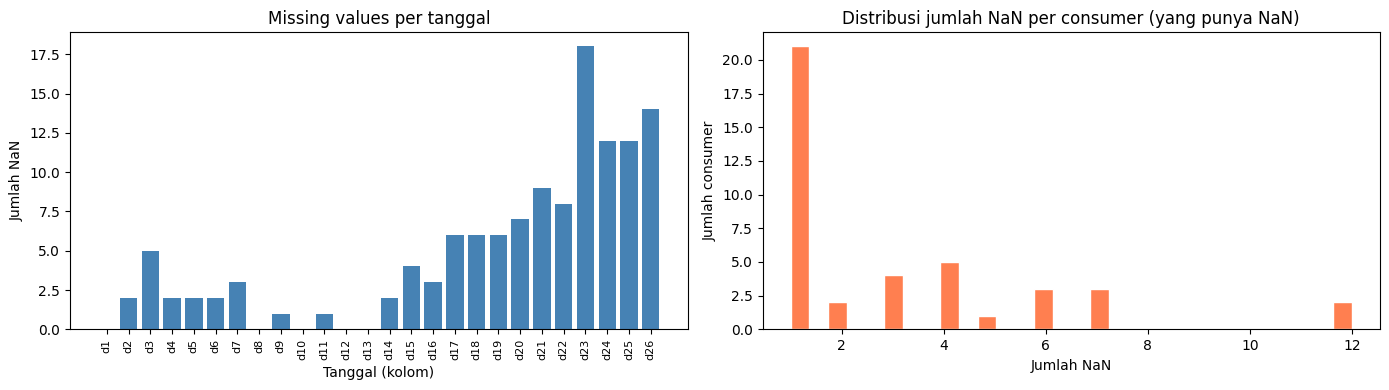

In [12]:
nan_per_col = df[date_cols].isna().sum()
nan_per_row = df[date_cols].isna().sum(axis=1)
n_nan_total = nan_per_col.sum()

print(f'Total NaN : {n_nan_total:,}  ({100*n_nan_total/(len(df)*T):.3f}% dari seluruh nilai)')
print(f'Consumer dengan ≥1 NaN: {(nan_per_row > 0).sum():,}')
print(f'Consumer dengan semua NaN: {(nan_per_row == T).sum():,}')
print(f'\nNaN per kolom (tanggal):')
print(nan_per_col[nan_per_col > 0].to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# NaN per kolom (tanggal)
axes[0].bar(range(len(date_cols)), nan_per_col.values, color='steelblue')
axes[0].set_xticks(range(len(date_cols)))
axes[0].set_xticklabels([f'd{i+1}' for i in range(len(date_cols))], rotation=90, fontsize=8)
axes[0].set_title('Missing values per tanggal')
axes[0].set_ylabel('Jumlah NaN')
axes[0].set_xlabel('Tanggal (kolom)')

# Distribusi jumlah NaN per consumer
axes[1].hist(nan_per_row[nan_per_row > 0], bins=30, color='coral', edgecolor='white')
axes[1].set_title('Distribusi jumlah NaN per consumer (yang punya NaN)')
axes[1].set_xlabel('Jumlah NaN')
axes[1].set_ylabel('Jumlah consumer')

plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_sgcc_nan_map.png', dpi=120, bbox_inches='tight')
plt.show()

## 3. Distribusi Label

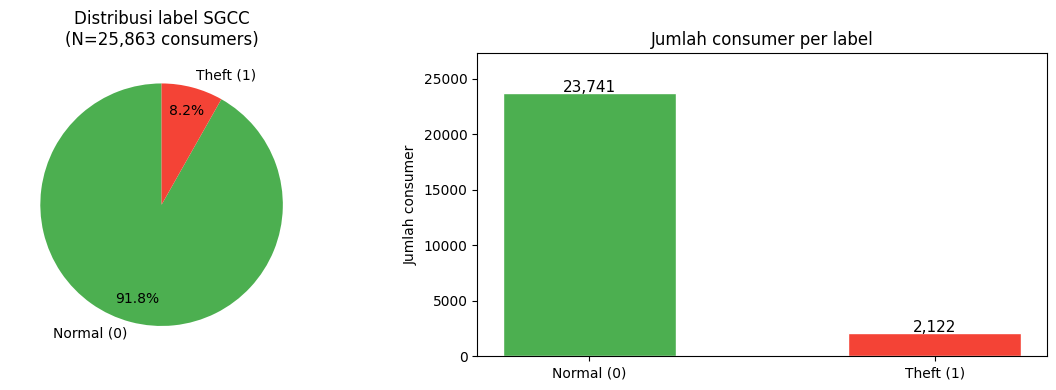

Class imbalance: 8.2% theft  →   sangat imbalanced


In [13]:
counts = df['FLAG'].value_counts().sort_index()
labels_pie = ['Normal (0)', 'Theft (1)']
colors_pie  = ['#4CAF50', '#F44336']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pie chart
axes[0].pie(counts.values, labels=labels_pie, colors=colors_pie,
            autopct='%1.1f%%', startangle=90, pctdistance=0.8)
axes[0].set_title(f'Distribusi label SGCC\n(N={len(df):,} consumers)')

# Bar chart
bars = axes[1].bar(labels_pie, counts.values, color=colors_pie, width=0.5, edgecolor='white')
for bar, val in zip(bars, counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                 f'{val:,}', ha='center', fontsize=11)
axes[1].set_title('Jumlah consumer per label')
axes[1].set_ylabel('Jumlah consumer')
axes[1].set_ylim(0, counts.max() * 1.15)

plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_sgcc_label_dist.png', dpi=120, bbox_inches='tight')
plt.show()

ratio = counts[1] / len(df)
print(f'Class imbalance: {ratio*100:.1f}% theft  →  ',
      'sangat imbalanced' if ratio < 0.1 else 'moderat')

## 4. Distribusi kWh (raw, per-label)

C:\Users\Maulana K. Adhitya\AppData\Local\Temp\ipykernel_23536\470507418.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot([normal_vals[normal_vals <= clip],


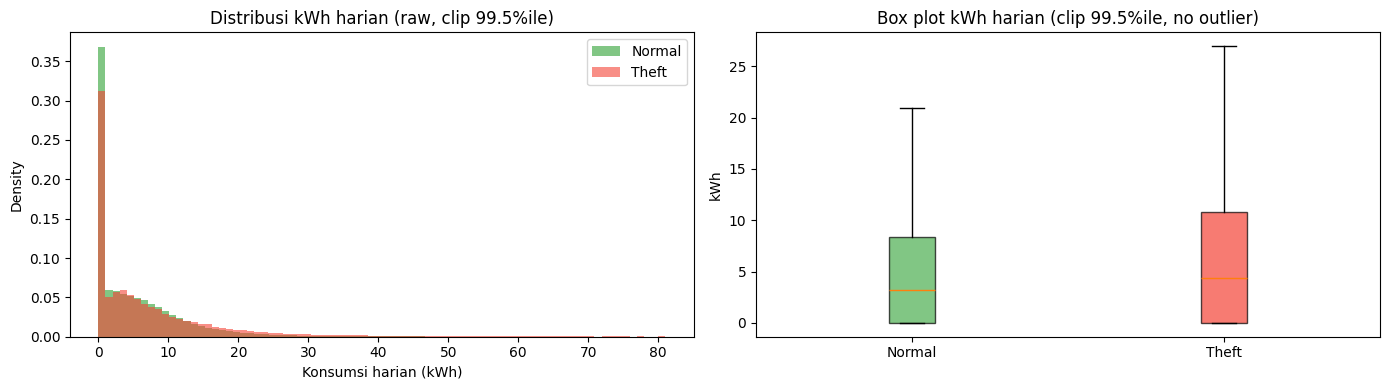

Normal: mean=6.1  median=3.2  std=15.3
Theft : mean=28.6  median=4.6  std=2232.6


In [14]:
normal_vals = df[df['FLAG'] == 0][date_cols].values.astype(float).flatten()
theft_vals  = df[df['FLAG'] == 1][date_cols].values.astype(float).flatten()
normal_vals = normal_vals[~np.isnan(normal_vals)]
theft_vals  = theft_vals[~np.isnan(theft_vals)]

# Clip outlier ekstrem untuk visualisasi (99.5th percentile)
clip = np.percentile(np.concatenate([normal_vals, theft_vals]), 99.5)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(normal_vals[normal_vals <= clip], bins=80, color='#4CAF50',
             alpha=0.7, label='Normal', density=True)
axes[0].hist(theft_vals[theft_vals <= clip],  bins=80, color='#F44336',
             alpha=0.6, label='Theft',  density=True)
axes[0].set_title('Distribusi kWh harian (raw, clip 99.5%ile)')
axes[0].set_xlabel('Konsumsi harian (kWh)')
axes[0].set_ylabel('Density')
axes[0].legend()

# Box plot
bp = axes[1].boxplot([normal_vals[normal_vals <= clip],
                       theft_vals[theft_vals <= clip]],
                      labels=['Normal', 'Theft'], patch_artist=True,
                      showfliers=False)
for patch, color in zip(bp['boxes'], ['#4CAF50', '#F44336']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].set_title('Box plot kWh harian (clip 99.5%ile, no outlier)')
axes[1].set_ylabel('kWh')

plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_sgcc_kwh_dist.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Normal: mean={normal_vals.mean():.1f}  median={np.median(normal_vals):.1f}  '
      f'std={normal_vals.std():.1f}')
print(f'Theft : mean={theft_vals.mean():.1f}  median={np.median(theft_vals):.1f}  '
      f'std={theft_vals.std():.1f}')

## 5. Profil time series: Normal vs Theft (sampel)

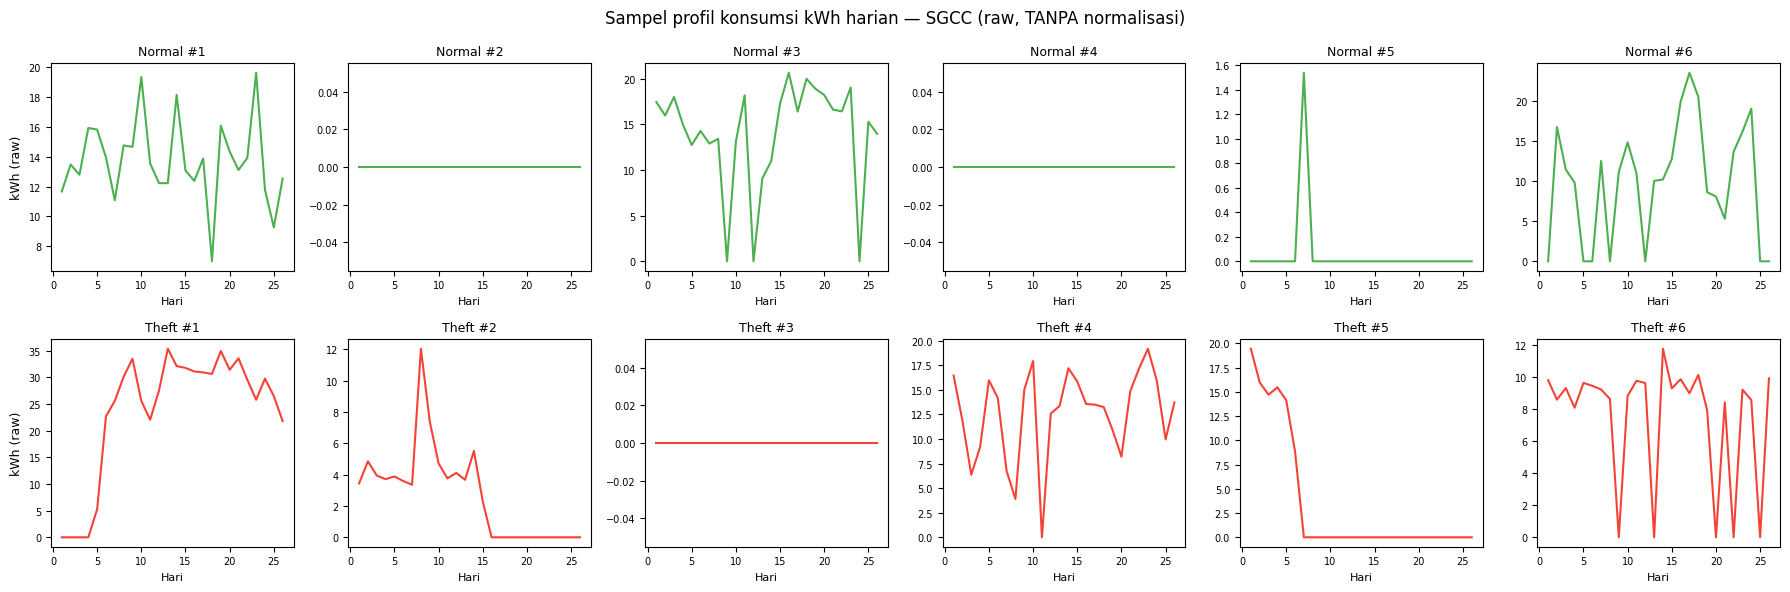

Nilai pada sumbu y adalah kWh ASLI (raw) — bukan ternormalisasi.


In [15]:
# Fill NaN untuk visualisasi (interpolasi linear, sama seperti preprocess)
def fill_row(row):
    s = pd.Series(row, dtype=float)
    s = s.interpolate(method='linear', limit_direction='both')
    return s.ffill().bfill().fillna(0.0).values

rng = np.random.RandomState(42)
N_SAMPLES = 6

normal_idx = df[df['FLAG'] == 0].index
theft_idx  = df[df['FLAG'] == 1].index
sel_normal = rng.choice(normal_idx, N_SAMPLES, replace=False)
sel_theft  = rng.choice(theft_idx,  N_SAMPLES, replace=False)

x = np.arange(1, T + 1)  # hari ke-1 .. 26

fig, axes = plt.subplots(2, N_SAMPLES, figsize=(18, 6), sharey=False)

for col_i, idx in enumerate(sel_normal):
    vals = fill_row(df.loc[idx, date_cols].values)
    axes[0, col_i].plot(x, vals, color='#4CAF50', linewidth=1.5)
    axes[0, col_i].set_title(f'Normal #{col_i+1}', fontsize=9)
    axes[0, col_i].set_xlabel('Hari', fontsize=8)
    if col_i == 0:
        axes[0, col_i].set_ylabel('kWh (raw)', fontsize=9)
    axes[0, col_i].tick_params(labelsize=7)

for col_i, idx in enumerate(sel_theft):
    vals = fill_row(df.loc[idx, date_cols].values)
    axes[1, col_i].plot(x, vals, color='#F44336', linewidth=1.5)
    axes[1, col_i].set_title(f'Theft #{col_i+1}', fontsize=9)
    axes[1, col_i].set_xlabel('Hari', fontsize=8)
    if col_i == 0:
        axes[1, col_i].set_ylabel('kWh (raw)', fontsize=9)
    axes[1, col_i].tick_params(labelsize=7)

fig.suptitle('Sampel profil konsumsi kWh harian — SGCC (raw, TANPA normalisasi)', fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_sgcc_profiles.png', dpi=120, bbox_inches='tight')
plt.show()
print('Nilai pada sumbu y adalah kWh ASLI (raw) — bukan ternormalisasi.')

## 6. Verifikasi urutan pipeline: Tidak ada normalisasi sebelum injeksi

In [16]:
# Simulasi alur CARLA untuk satu consumer
# Cek: data di SGCC(train=True) harus RAW (bukan ternormalisasi)

processed_ok = PROCESSED_DIR.exists() and (PROCESSED_DIR / 'data').exists()

if processed_ok:
    from data.SGCC import SGCC

    # Ambil consumer pertama dari train_list
    train_list_path = PROCESSED_DIR / 'train_list.txt'
    with open(train_list_path) as f:
        train_files = [l.strip() for l in f if l.strip()]
    fname = train_files[0]
    print(f'Consumer uji: {fname}')

    ds_train = SGCC(fname, train=True)
    ds_test  = SGCC(fname, train=False)

    # Ambil window pertama
    w_train = ds_train[0]['ts_org'].cpu().numpy()  # harus RAW
    w_test  = ds_test[0]['ts_org'].cpu().numpy()   # harus ternormalisasi

    print(f'\ntrain[0] window stats (harus raw kWh, nilai besar):')
    print(f'  min={w_train.min():.2f}  max={w_train.max():.2f}  '
          f'mean={w_train.mean():.2f}')
    raw_check = w_train.max() > 10  # raw kWh pasti >> 1
    print(f'  max > 10 → raw kWh:  {"✓ BENAR" if raw_check else "✗ SALAH — data sudah ternormalisasi!"}')

    print(f'\ntest[0] window stats (harus ternormalisasi, skala kecil):')
    print(f'  min={w_test.min():.4f}  max={w_test.max():.4f}  '
          f'mean={w_test.mean():.4f}')
    norm_check = abs(w_test.mean()) < 3  # normalized harusnya dekat 0
    print(f'  mean dekat 0 → ternormalisasi: {"✓ BENAR" if norm_check else "✗ SALAH"}')

    mean_info, std_info = ds_train.get_info()
    print(f'\nget_info() dari train:')
    print(f'  mean={mean_info}  std={std_info}')
    print(f'  std ≠ 1.0 → bukan dummy (0,1): {"✓ BENAR" if std_info[0] != 1.0 else "✗ SALAH — masih mengembalikan dummy std=1"}')

    print('\n✓ Pipeline BENAR: train=True menyimpan raw; get_info() return mean/std asli.')
    print('  AugmentedDataset.create_pairs(): attack(ts_raw) → normalize ← order Jokar 2016.')
else:
    print('[INFO] Processed dir belum ada. Jalankan preprocess_sgcc.py dulu, lalu re-run cell ini.')
    print('  python preprocess_sgcc.py')

Consumer uji: 21C9A84E413F7820438D8321B3C0A73A.npy

train[0] window stats (harus raw kWh, nilai besar):
  min=11.08  max=15.93  mean=13.53
  max > 10 → raw kWh:  ✓ BENAR

test[0] window stats (harus ternormalisasi, skala kecil):
  min=-0.9678  max=0.8125  mean=-0.0679
  mean dekat 0 → ternormalisasi: ✓ BENAR

get_info() dari train:
  mean=[13.71653836]  std=[2.72436148]
  std ≠ 1.0 → bukan dummy (0,1): ✓ BENAR

✓ Pipeline BENAR: train=True menyimpan raw; get_info() return mean/std asli.
  AugmentedDataset.create_pairs(): attack(ts_raw) → normalize ← order Jokar 2016.


## 7. Window size analysis

T (timestamps per consumer) = 26
Stride = 1
AugmentedDataset: positive pair ada saat index > 10

   W   n_windows   n_pos_pairs    cukup (≥5)
--------------------------------------------
   2          24            13             ✓
   3          23            12             ✓
   4          22            11             ✓
   5          21            10             ✓
   6          20             9             ✓
   7          19             8             ✓
   8          18             7             ✓
   9          17             6             ✓
  10          16             5             ✓
  11          15             4             ✗
  12          14             3             ✗
  13          13             2             ✗
  14          12             1             ✗

→ Window size maksimum untuk ≥5 positive pairs: W = 10
→ Dengan W=7 (weekly pattern):  8 positive pairs


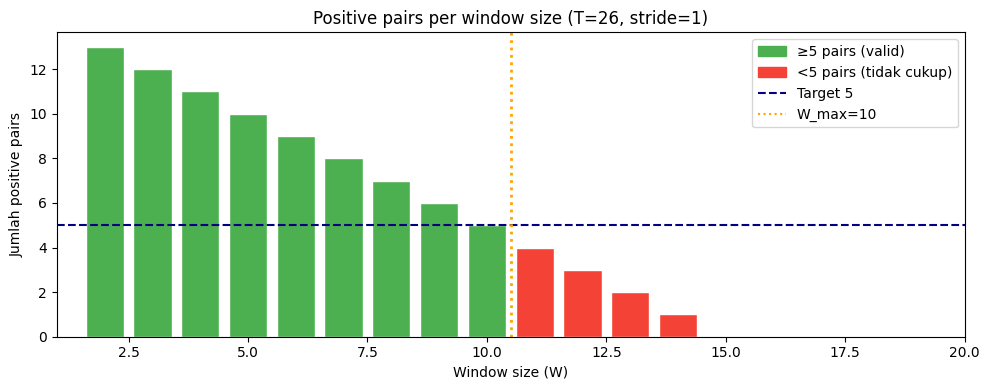

In [17]:
# Analisis matematis window size untuk SGCC
# create_pairs() CARLA: positive pair hanya ada jika index > 10

T_SGCC  = T      # 26
STRIDE  = 1
MIN_IDX = 10     # index > 10 → true temporal neighbor

print(f'T (timestamps per consumer) = {T_SGCC}')
print(f'Stride = {STRIDE}')
print(f'AugmentedDataset: positive pair ada saat index > {MIN_IDX}\n')
print(f'{"W":>4}  {"n_windows":>10}  {"n_pos_pairs":>12}  {"cukup (≥5)":>12}')
print('-' * 44)

results = []
for W in range(2, T_SGCC):
    n_win = int((T_SGCC - W) / STRIDE)    # = T - W  saat stride=1
    n_pos = max(0, n_win - 1 - MIN_IDX)   # index > 10, index 0..n_win-1
    ok    = '✓' if n_pos >= 5 else '✗'
    results.append((W, n_win, n_pos, n_pos >= 5))
    if W <= 14:
        print(f'{W:>4}  {n_win:>10}  {n_pos:>12}  {ok:>12}')

W_max = max(W for W, _, _, ok in results if ok)
W_weekly = 7  # domain-informed choice

print(f'\n→ Window size maksimum untuk ≥5 positive pairs: W = {W_max}')
print(f'→ Dengan W={W_weekly} (weekly pattern): ',
      dict((W, n) for W, _, n, _ in results)[W_weekly], 'positive pairs')

fig, ax = plt.subplots(figsize=(10, 4))
ws  = [r[0] for r in results]
nps = [r[2] for r in results]
colors_bar = ['#4CAF50' if r[3] else '#F44336' for r in results]
ax.bar(ws, nps, color=colors_bar, width=0.8, edgecolor='white')
ax.axhline(5, color='navy', linestyle='--', linewidth=1.5, label='Target ≥5 pairs')
ax.axvline(W_max + 0.5, color='orange', linestyle=':', linewidth=2,
           label=f'W_max={W_max}')
ax.set_xlabel('Window size (W)')
ax.set_ylabel('Jumlah positive pairs')
ax.set_title(f'Positive pairs per window size (T={T_SGCC}, stride={STRIDE})')
ax.legend()
ax.set_xlim(1, 20)
green_patch = mpatches.Patch(color='#4CAF50', label='≥5 pairs (valid)')
red_patch   = mpatches.Patch(color='#F44336', label='<5 pairs (tidak cukup)')
ax.legend(handles=[green_patch, red_patch,
                    plt.Line2D([0],[0], color='navy', linestyle='--', label='Target 5'),
                    plt.Line2D([0],[0], color='orange', linestyle=':', label=f'W_max={W_max}')])
plt.tight_layout()
plt.savefig(FIG_DIR / 'eda_sgcc_window_size.png', dpi=120, bbox_inches='tight')
plt.show()

## 8. Ringkasan pipeline

In [ ]:
print('=' * 65)
print('RINGKASAN PIPELINE SGCC → CARLA')
print('=' * 65)
print()
print('1. preprocess_sgcc.py')
print('   • Baca wide CSV (25863 consumers × 26 timestamp + CONS_NO + FLAG)')
print('   • Isi NaN: interpolasi linear, ffill/bfill, fallback 0')
print('   • Simpan tiap consumer sebagai .npy (26, 1) float32  ← RAW kWh')
print('   • ⚠ TIDAK ada normalisasi di sini')
print('   • Split: train (normal) / val (mixed) / test (mixed)')
print()
print('2. data/SGCC.py  (saat training, train=True)')
print('   • Load .npy → hitung mean, std per consumer')
print('   • Simpan data RAW (TIDAK dinormalisasi)')
print('   • get_info() → (mean, std) asli untuk AugmentedDataset')
print()
print('3. AugmentedDataset.create_pairs()')
print('   • ts_raw  = SGCC.__getitem__(i)["ts_org"]  ← raw kWh')
print('   • ts_aug  = attack(ts_raw)                  ← EAI di ruang kWh ✓')
print('   • ts_norm = (ts_aug - mean) / std           ← normalize setelah attack ✓')
print()
print('4. data/SGCC.py  (saat evaluasi, train=False)')
print('   • Normalisasi di __init__: (ts_raw - mean) / std')
print('   • Model menerima input ternormalisasi langsung')
print()
print('Window size:')
print(f'   T=26, stride=1 → W ≤ 10 untuk ≥5 positive pairs')
print(f'   Rekomendasi: W=7 (weekly) atau W=10 (minimal 5 pairs)')
print('=' * 65)

RINGKASAN PIPELINE SGCC → CARLA

1. preprocess_sgcc.py
   • Baca wide CSV (25863 consumers × 26 timestamp + CONS_NO + FLAG)
   • Isi NaN: interpolasi linear, ffill/bfill, fallback 0
   • Simpan tiap consumer sebagai .npy (26, 1) float32  ← RAW kWh
   • ⚠ TIDAK ada normalisasi di sini
   • Split: train (normal) / val (mixed) / test (mixed)

2. data/SGCC.py  (saat training, train=True)
   • Load .npy → hitung mean, std per consumer
   • Simpan data RAW (TIDAK dinormalisasi)
   • get_info() → (mean, std) asli untuk AugmentedDataset

3. AugmentedDataset.create_pairs()
   • ts_raw  = SGCC.__getitem__(i)["ts_org"]  ← raw kWh
   • ts_aug  = attack(ts_raw)                  ← EAI di ruang kWh ✓
   • ts_norm = (ts_aug - mean) / std           ← normalize setelah attack ✓

4. data/SGCC.py  (saat evaluasi, train=False)
   • Normalisasi di __init__: (ts_raw - mean) / std
   • Model menerima input ternormalisasi langsung

Window size:
   T=26, stride=1 → W ≤ 10 untuk ≥5 positive pairs
   Rekomendasi:

: 